In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo


In [2]:
heart = fetch_ucirepo(id=45)
X = heart.data.features
y = heart.data.targets
df = pd.concat([X, y], axis=1)
df.to_csv("../data/raw/heart_disease_raw.csv", index=False)

In [3]:
print(df.shape)
print(df.columns.tolist())
print(df.isna().sum())
print(df.dtypes)
df.describe()

(303, 14)
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [4]:
print(df["num"].value_counts().sort_index())
df[df.isna().any(axis=1)]

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0


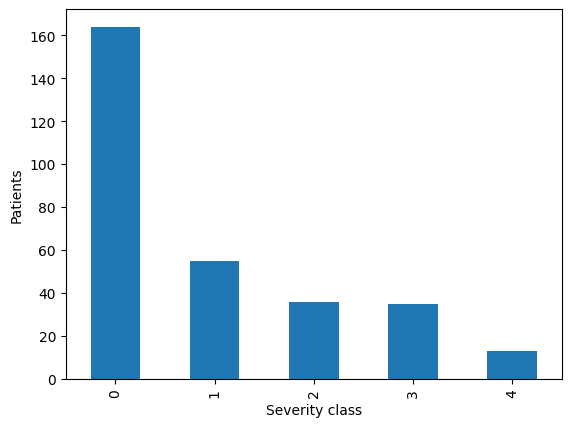

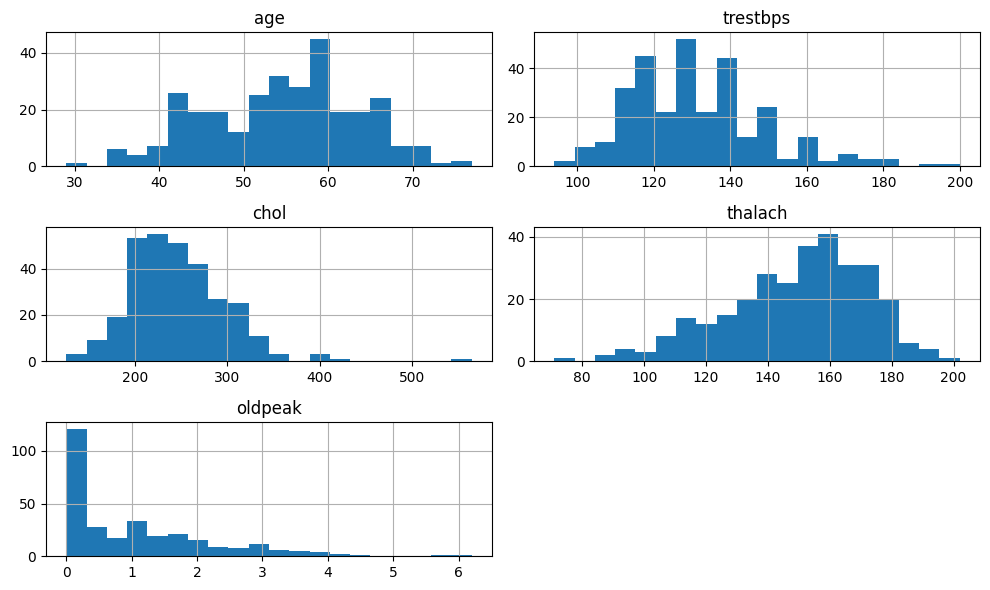

In [5]:
df["num"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Severity class"); plt.ylabel("Patients")
plt.savefig("../results/figures/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

df[["age", "trestbps", "chol", "thalach", "oldpeak"]].hist(bins=20, figsize=(10, 6))
plt.tight_layout()
plt.savefig("../results/figures/feature_distributions.png", dpi=150)
plt.show()

In [6]:
df = pd.read_csv("../data/raw/heart_disease_raw.csv")
df = df.dropna().reset_index(drop=True)
print(df.shape)   # expect (297, 14)

(297, 14)


In [7]:
cat_cols = ["cp", "restecg", "slope", "thal"]
df_enc = pd.get_dummies(df, columns=cat_cols, dtype=float)

feature_names = [c for c in df_enc.columns if c != "num"]
X = df_enc[feature_names].values.astype(np.float32)
y = df_enc["num"].values.astype(np.int64)
print(X.shape)    # expect (297, 22)

cont_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
cont_idx = [feature_names.index(c) for c in cont_cols]

(297, 22)


In [8]:
import torch, torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

class MLP(nn.Module):
    def __init__(self, in_dim, n_classes=5, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_classes),
        )
    def forward(self, x):
        return self.net(x)

In [9]:
torch.manual_seed(42); np.random.seed(42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_probs = np.zeros((len(y), 5), dtype=np.float32)
fold_acc = []

for fold, (tr, va) in enumerate(skf.split(X, y)):
    Xtr, Xva = X[tr].copy(), X[va].copy()
    scaler = StandardScaler()
    Xtr[:, cont_idx] = scaler.fit_transform(Xtr[:, cont_idx])   # fit on train only
    Xva[:, cont_idx] = scaler.transform(Xva[:, cont_idx])

    Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(y[tr])
    Xva_t = torch.tensor(Xva)

    model = MLP(X.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()

    for epoch in range(100):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xtr_t), ytr_t)
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(Xva_t), dim=1).numpy()
    oof_probs[va] = probs
    acc = (probs.argmax(1) == y[va]).mean()
    fold_acc.append(acc)
    print(f"fold {fold}: acc={acc:.3f}, final train loss={loss.item():.3f}")

print(f"mean acc = {np.mean(fold_acc):.3f} ± {np.std(fold_acc):.3f}")
print("predicted class counts:", np.bincount(oof_probs.argmax(1), minlength=5))

np.save("../results/metrics/baseline_oof_probs.npy", oof_probs)
np.save("../results/metrics/y.npy", y)

fold 0: acc=0.633, final train loss=0.712
fold 1: acc=0.567, final train loss=0.691
fold 2: acc=0.542, final train loss=0.687
fold 3: acc=0.627, final train loss=0.702
fold 4: acc=0.610, final train loss=0.723
mean acc = 0.596 ± 0.035
predicted class counts: [180  36  28  53   0]


In [10]:
from sklearn.model_selection import train_test_split

tr, va = next(iter(skf.split(X, y)))        # fold 0 only
tr_in, val_in = train_test_split(tr, test_size=0.2, stratify=y[tr], random_state=0)

scaler = StandardScaler()
Xa, Xb = X[tr_in].copy(), X[val_in].copy()
Xa[:, cont_idx] = scaler.fit_transform(Xa[:, cont_idx])
Xb[:, cont_idx] = scaler.transform(Xb[:, cont_idx])
Xa_t, ya_t = torch.tensor(Xa), torch.tensor(y[tr_in])
Xb_t, yb_t = torch.tensor(Xb), torch.tensor(y[val_in])

torch.manual_seed(42)
model = MLP(X.shape[1])
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(1, 801):
    model.train(); opt.zero_grad()
    loss = loss_fn(model(Xa_t), ya_t); loss.backward(); opt.step()
    if epoch in (50, 100, 200, 400, 800):
        model.eval()
        with torch.no_grad():
            vloss = loss_fn(model(Xb_t), yb_t).item()
        print(f"epoch {epoch}: train loss={loss.item():.3f}, inner val loss={vloss:.3f}")

epoch 50: train loss=0.941, inner val loss=1.061
epoch 100: train loss=0.679, inner val loss=0.966
epoch 200: train loss=0.224, inner val loss=1.341
epoch 400: train loss=0.014, inner val loss=2.468
epoch 800: train loss=0.002, inner val loss=3.059


In [11]:
from sklearn.metrics import confusion_matrix
pred = oof_probs.argmax(1)
print("majority-class accuracy:", round((y == 0).mean(), 3))
print(confusion_matrix(y, pred))


majority-class accuracy: 0.539
[[145   9   3   3   0]
 [ 26   8   6  14   0]
 [  7   7   7  14   0]
 [  2   7   9  17   0]
 [  0   5   3   5   0]]


In [12]:
class MLPDrop(nn.Module):
    def __init__(self, in_dim, n_classes=5, hidden=64, p=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, n_classes),
        )
    def forward(self, x):
        return self.net(x)

In [13]:
torch.manual_seed(42); np.random.seed(42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # same splits as baseline
T = 50
mc_probs = np.zeros((T, len(y), 5), dtype=np.float32)
fold_acc = []

for fold, (tr, va) in enumerate(skf.split(X, y)):
    Xtr, Xva = X[tr].copy(), X[va].copy()
    scaler = StandardScaler()
    Xtr[:, cont_idx] = scaler.fit_transform(Xtr[:, cont_idx])
    Xva[:, cont_idx] = scaler.transform(Xva[:, cont_idx])
    Xtr_t, ytr_t, Xva_t = torch.tensor(Xtr), torch.tensor(y[tr]), torch.tensor(Xva)

    model = MLPDrop(X.shape[1], p=0.2)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()

    for epoch in range(100):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xtr_t), ytr_t)
        loss.backward()
        opt.step()

    model.train()   # deliberately keep dropout ON at prediction time
    with torch.no_grad():
        passes = torch.stack([torch.softmax(model(Xva_t), dim=1) for _ in range(T)])
    mc_probs[:, va, :] = passes.numpy()

    mean_p = passes.mean(0).numpy()
    acc = (mean_p.argmax(1) == y[va]).mean()
    fold_acc.append(acc)
    print(f"fold {fold}: acc={acc:.3f}, train loss={loss.item():.3f}, "
          f"mean std across passes={passes.std(0).mean().item():.4f}")

oof_mc = mc_probs.mean(0)
print(f"mean acc = {np.mean(fold_acc):.3f} ± {np.std(fold_acc):.3f}")
print("predicted class counts:", np.bincount(oof_mc.argmax(1), minlength=5))

np.save("../results/metrics/mcdropout_oof_probs.npy", oof_mc)
np.save("../results/metrics/mcdropout_passes.npy", mc_probs)

fold 0: acc=0.650, train loss=0.796, mean std across passes=0.0290
fold 1: acc=0.533, train loss=0.751, mean std across passes=0.0322
fold 2: acc=0.542, train loss=0.736, mean std across passes=0.0381
fold 3: acc=0.644, train loss=0.818, mean std across passes=0.0348
fold 4: acc=0.627, train loss=0.780, mean std across passes=0.0307
mean acc = 0.599 ± 0.051
predicted class counts: [187  32  24  54   0]


In [14]:
torch.manual_seed(42); np.random.seed(42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
M = 10
ens_members = np.zeros((M, len(y), 5), dtype=np.float32)
fold_acc = []

for fold, (tr, va) in enumerate(skf.split(X, y)):
    Xtr, Xva = X[tr].copy(), X[va].copy()
    scaler = StandardScaler()
    Xtr[:, cont_idx] = scaler.fit_transform(Xtr[:, cont_idx])
    Xva[:, cont_idx] = scaler.transform(Xva[:, cont_idx])
    Xtr_t, ytr_t, Xva_t = torch.tensor(Xtr), torch.tensor(y[tr]), torch.tensor(Xva)

    for m in range(M):
        torch.manual_seed(1000 * fold + m)          # different init per member
        model = MLP(X.shape[1])
        opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
        loss_fn = nn.CrossEntropyLoss()
        for epoch in range(100):
            model.train(); opt.zero_grad()
            loss_fn(model(Xtr_t), ytr_t).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            ens_members[m, va, :] = torch.softmax(model(Xva_t), dim=1).numpy()

    acc = (ens_members[:, va, :].mean(0).argmax(1) == y[va]).mean()
    fold_acc.append(acc)
    print(f"fold {fold}: ensemble acc={acc:.3f}")

oof_ens = ens_members.mean(0)
print(f"mean acc = {np.mean(fold_acc):.3f} ± {np.std(fold_acc):.3f}")
print("predicted class counts:", np.bincount(oof_ens.argmax(1), minlength=5))
np.save("../results/metrics/ensemble_oof_probs.npy", oof_ens)


fold 0: ensemble acc=0.683
fold 1: ensemble acc=0.533
fold 2: ensemble acc=0.525
fold 3: ensemble acc=0.627
fold 4: ensemble acc=0.644
mean acc = 0.603 ± 0.063
predicted class counts: [182  37  32  46   0]


In [15]:
import torch.nn.functional as F

class BayesLinear(nn.Module):
    def __init__(self, i, o, prior_sigma=1.0):
        super().__init__()
        self.w_mu  = nn.Parameter(torch.empty(o, i).normal_(0, 0.1))
        self.w_rho = nn.Parameter(torch.full((o, i), -3.0))
        self.b_mu  = nn.Parameter(torch.zeros(o))
        self.b_rho = nn.Parameter(torch.full((o,), -3.0))
        self.ps = prior_sigma
    def forward(self, x):
        w_sig, b_sig = F.softplus(self.w_rho), F.softplus(self.b_rho)
        w = self.w_mu + w_sig * torch.randn_like(w_sig)    # reparameterisation trick
        b = self.b_mu + b_sig * torch.randn_like(b_sig)
        self.kl = sum((torch.log(self.ps / s) + (s**2 + mu**2) / (2 * self.ps**2) - 0.5).sum()
                      for mu, s in ((self.w_mu, w_sig), (self.b_mu, b_sig)))
        return F.linear(x, w, b)

class BayesMLP(nn.Module):
    def __init__(self, in_dim, n_classes=5, hidden=64):
        super().__init__()
        self.l1, self.l2, self.l3 = BayesLinear(in_dim, hidden), BayesLinear(hidden, hidden), BayesLinear(hidden, n_classes)
    def forward(self, x):
        return self.l3(F.relu(self.l2(F.relu(self.l1(x)))))
    def kl(self):
        return self.l1.kl + self.l2.kl + self.l3.kl

def train_bnn(Xt, yt, epochs, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    model = BayesMLP(Xt.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    N = len(yt)
    for _ in range(epochs):
        opt.zero_grad()
        logits = model(Xt)
        loss = F.cross_entropy(logits, yt) + model.kl() / N    # negative ELBO per example
        loss.backward(); opt.step()
    return model

def predict_bnn(model, Xt, S=50):
    with torch.no_grad():
        return torch.stack([torch.softmax(model(Xt), dim=1) for _ in range(S)]).mean(0).numpy()

In [22]:
E_VI = 600    # <- replace with your chosen value
oof_vi = np.zeros((len(y), 5), dtype=np.float32)
fold_acc = []

for fold, (tr, va) in enumerate(skf.split(X, y)):
    Xtr, Xva = X[tr].copy(), X[va].copy()
    scaler = StandardScaler()
    Xtr[:, cont_idx] = scaler.fit_transform(Xtr[:, cont_idx])
    Xva[:, cont_idx] = scaler.transform(Xva[:, cont_idx])
    model = train_bnn(torch.tensor(Xtr), torch.tensor(y[tr]), E_VI, seed=fold)
    oof_vi[va] = predict_bnn(model, torch.tensor(Xva), S=50)
    acc = (oof_vi[va].argmax(1) == y[va]).mean()
    fold_acc.append(acc)
    print(f"fold {fold}: acc={acc:.3f}")

print(f"mean acc = {np.mean(fold_acc):.3f} ± {np.std(fold_acc):.3f}")
print("predicted class counts:", np.bincount(oof_vi.argmax(1), minlength=5))
np.save("../results/metrics/vi_oof_probs.npy", oof_vi)

fold 0: acc=0.617
fold 1: acc=0.517
fold 2: acc=0.508
fold 3: acc=0.576
fold 4: acc=0.593
mean acc = 0.562 ± 0.043
predicted class counts: [176  39  40  37   5]


          method    acc    ECE     ECE_95CI  Brier    NLL  mean_conf
0       Baseline  0.596  0.074  0.055-0.131  0.500  0.957      0.663
1     MC Dropout  0.599  0.059  0.041-0.116  0.486  0.938      0.641
2  Deep Ensemble  0.603  0.081  0.059-0.132  0.503  0.965      0.662
3       VI (BBB)  0.596  0.066  0.051-0.119  0.505  0.972      0.661


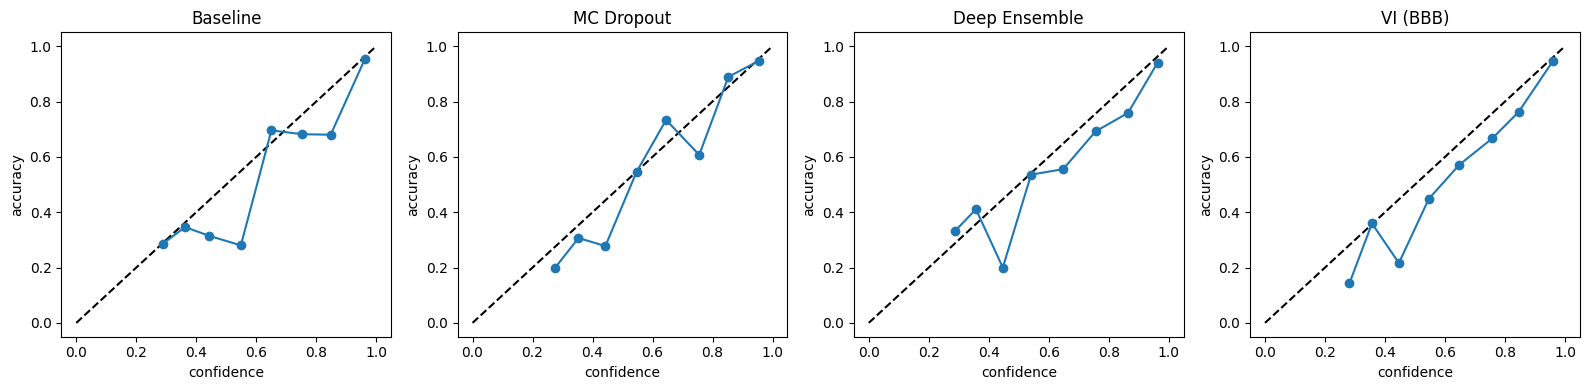

In [25]:
def ece_score(p, y, n_bins=10):
    conf, pred = p.max(1), p.argmax(1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return ece

def brier(p, y):
    return ((p - np.eye(5)[y]) ** 2).sum(1).mean()

def nll(p, y):
    return -np.log(p[np.arange(len(y)), y] + 1e-9).mean()

methods = {
    "Baseline": np.load("../results/metrics/baseline_oof_probs.npy"),
    "MC Dropout": np.load("../results/metrics/mcdropout_oof_probs.npy"),
    "Deep Ensemble": np.load("../results/metrics/ensemble_oof_probs.npy"),
    "VI (BBB)": np.load("../results/metrics/vi_E200_oof_probs.npy"),
}

rng = np.random.default_rng(0)
rows = []
for name, p in methods.items():
    boots = [ece_score(p[i], y[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(500))]
    rows.append(dict(method=name, acc=(p.argmax(1) == y).mean(), ECE=ece_score(p, y),
                     ECE_95CI=f"{np.percentile(boots,2.5):.3f}-{np.percentile(boots,97.5):.3f}",
                     Brier=brier(p, y), NLL=nll(p, y), mean_conf=p.max(1).mean()))
res = pd.DataFrame(rows).round(3)
print(res)
res.to_csv("../results/metrics/calibration_summary.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, p) in zip(axes, methods.items()):
    conf, correct = p.max(1), (p.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, 11); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5: xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot([0, 1], [0, 1], "k--"); ax.plot(xs, ys, "o-")
    ax.set_title(name); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
plt.tight_layout()
plt.savefig("../results/figures/reliability_diagrams.png", dpi=150)
plt.show()

In [26]:
def paired_boot(pa, pb, y, metric, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(metric(pa[i], y[i]) - metric(pb[i], y[i]))
    return np.mean(d), np.percentile(d, [2.5, 97.5])

for name in ["MC Dropout", "Deep Ensemble", "VI (BBB)"]:
    for mname, f in [("Brier", brier), ("NLL", nll)]:
        m, ci = paired_boot(methods[name], methods["Baseline"], y, f)
        print(name, mname, round(m, 3), ci.round(3))

MC Dropout Brier -0.014 [-0.027 -0.001]
MC Dropout NLL -0.019 [-0.047  0.008]
Deep Ensemble Brier 0.003 [-0.006  0.014]
Deep Ensemble NLL 0.008 [-0.012  0.029]
VI (BBB) Brier 0.005 [-0.007  0.017]
VI (BBB) NLL 0.015 [-0.009  0.039]


In [19]:
for E in (25, 50, 100, 200, 300, 600):
    m = train_bnn(Xa_t, ya_t, E)
    pv = predict_bnn(m, Xb_t)
    nll_v = -np.log(pv[np.arange(len(yb_t)), yb_t.numpy()] + 1e-9).mean()
    print(f"epochs {E}: inner val NLL={nll_v:.3f}")
    

epochs 25: inner val NLL=1.326
epochs 50: inner val NLL=1.123
epochs 100: inner val NLL=0.968
epochs 200: inner val NLL=0.954
epochs 300: inner val NLL=0.949
epochs 600: inner val NLL=0.983


In [20]:
E_VI = 200
oof_vi = np.zeros((len(y), 5), dtype=np.float32)
fold_acc = []
for fold, (tr, va) in enumerate(skf.split(X, y)):
    Xtr, Xva = X[tr].copy(), X[va].copy()
    scaler = StandardScaler()
    Xtr[:, cont_idx] = scaler.fit_transform(Xtr[:, cont_idx])
    Xva[:, cont_idx] = scaler.transform(Xva[:, cont_idx])
    model = train_bnn(torch.tensor(Xtr), torch.tensor(y[tr]), E_VI, seed=fold)
    oof_vi[va] = predict_bnn(model, torch.tensor(Xva), S=50)
    fold_acc.append((oof_vi[va].argmax(1) == y[va]).mean())
    print(f"fold {fold}: acc={fold_acc[-1]:.3f}")
print(f"mean acc = {np.mean(fold_acc):.3f} ± {np.std(fold_acc):.3f}")
print("predicted class counts:", np.bincount(oof_vi.argmax(1), minlength=5))
np.save("../results/metrics/vi_oof_probs.npy", oof_vi)

fold 0: acc=0.667
fold 1: acc=0.567
fold 2: acc=0.508
fold 3: acc=0.610
fold 4: acc=0.627
mean acc = 0.596 ± 0.054
predicted class counts: [186  30  35  45   1]


In [21]:
oof_drop_det = np.zeros((len(y), 5), dtype=np.float32)
for fold, (tr, va) in enumerate(skf.split(X, y)):
    Xtr, Xva = X[tr].copy(), X[va].copy()
    scaler = StandardScaler()
    Xtr[:, cont_idx] = scaler.fit_transform(Xtr[:, cont_idx])
    Xva[:, cont_idx] = scaler.transform(Xva[:, cont_idx])
    torch.manual_seed(42 + fold)
    model = MLPDrop(X.shape[1], p=0.2)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    for _ in range(100):
        model.train(); opt.zero_grad()
        nn.CrossEntropyLoss()(model(torch.tensor(Xtr)), torch.tensor(y[tr])).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        oof_drop_det[va] = torch.softmax(model(torch.tensor(Xva)), dim=1).numpy()
print("dropout, eval mode: Brier", round(brier(oof_drop_det, y), 3), "NLL", round(nll(oof_drop_det, y), 3))

dropout, eval mode: Brier 0.493 NLL 0.945


In [23]:
E_VI = 200
oof_vi = np.zeros((len(y), 5), dtype=np.float32)
fold_acc = []

for fold, (tr, va) in enumerate(skf.split(X, y)):
    Xtr, Xva = X[tr].copy(), X[va].copy()
    scaler = StandardScaler()
    Xtr[:, cont_idx] = scaler.fit_transform(Xtr[:, cont_idx])
    Xva[:, cont_idx] = scaler.transform(Xva[:, cont_idx])
    model = train_bnn(torch.tensor(Xtr), torch.tensor(y[tr]), E_VI, seed=fold)
    oof_vi[va] = predict_bnn(model, torch.tensor(Xva), S=50)
    fold_acc.append((oof_vi[va].argmax(1) == y[va]).mean())
    print(f"fold {fold}: acc={fold_acc[-1]:.3f}")

print(f"mean acc = {np.mean(fold_acc):.3f} ± {np.std(fold_acc):.3f}")
print("predicted class counts:", np.bincount(oof_vi.argmax(1), minlength=5))
np.save("../results/metrics/vi_E200_oof_probs.npy", oof_vi)

fold 0: acc=0.667
fold 1: acc=0.567
fold 2: acc=0.508
fold 3: acc=0.610
fold 4: acc=0.627
mean acc = 0.596 ± 0.054
predicted class counts: [186  30  35  45   1]


In [27]:
from sklearn.metrics import roc_auc_score

def entropy(p):
    return -(p * np.log(p + 1e-12)).sum(1)

def auroc(p, y):
    correct = (p.argmax(1) == y).astype(int)
    return roc_auc_score(correct, -entropy(p))   # high score = confident, should mean correct

rng = np.random.default_rng(0)
idx = [rng.integers(0, len(y), len(y)) for _ in range(1000)]   # same resamples for every method

rows = []
for name, p in methods.items():
    boots = [auroc(p[i], y[i]) for i in idx]
    d = [auroc(p[i], y[i]) - auroc(methods["Baseline"][i], y[i]) for i in idx]
    rows.append(dict(method=name, AUROC=auroc(p, y),
                     CI=f"{np.percentile(boots,2.5):.3f}-{np.percentile(boots,97.5):.3f}",
                     diff_vs_baseline=np.mean(d),
                     diff_CI=f"{np.percentile(d,2.5):.3f} to {np.percentile(d,97.5):.3f}"))
auc_res = pd.DataFrame(rows).round(3)
print(auc_res)
auc_res.to_csv("../results/metrics/entropy_auroc.csv", index=False)

          method  AUROC           CI  diff_vs_baseline          diff_CI
0       Baseline  0.811  0.764-0.862             0.000   0.000 to 0.000
1     MC Dropout  0.820  0.768-0.868             0.009  -0.030 to 0.046
2  Deep Ensemble  0.800  0.750-0.848            -0.011  -0.047 to 0.025
3       VI (BBB)  0.816  0.767-0.862             0.005  -0.029 to 0.044


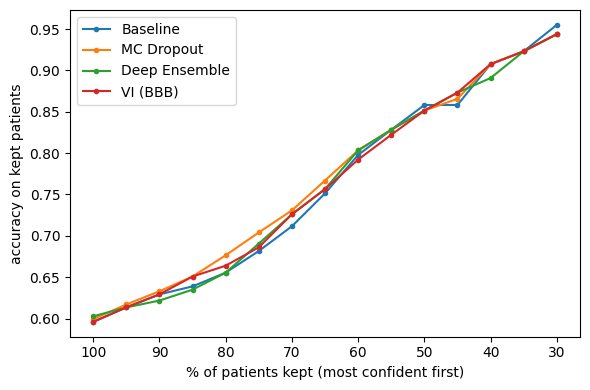

In [28]:
coverages = np.arange(1.0, 0.29, -0.05)
plt.figure(figsize=(6, 4))
for name, p in methods.items():
    order = np.argsort(entropy(p))                  # most confident first
    correct = (p.argmax(1) == y)[order]
    accs = [correct[:int(round(c * len(y)))].mean() for c in coverages]
    plt.plot(coverages * 100, accs, "o-", ms=3, label=name)
plt.gca().invert_xaxis()
plt.xlabel("% of patients kept (most confident first)")
plt.ylabel("accuracy on kept patients")
plt.legend(); plt.tight_layout()
plt.savefig("../results/figures/rejection_curve.png", dpi=150)
plt.show()

In [29]:
age = df["age"].values                      # df is the dropna'd frame, same row order as X
tr_idx = np.where(age <= 55)[0]
te_idx = np.where(age >= 61)[0]
print("train / test sizes:", len(tr_idx), len(te_idx))
print("train class counts:", np.bincount(y[tr_idx], minlength=5))
print("test  class counts:", np.bincount(y[te_idx], minlength=5))
print("majority-class acc on test:", round((y[te_idx] == 0).mean(), 3))

train / test sizes: 146 79
train class counts: [99 19  8 17  3]
test  class counts: [35 14 14 10  6]
majority-class acc on test: 0.443


In [30]:
def fit_predict_all(tr, te, seed):
    Xtr, Xte = X[tr].copy(), X[te].copy()
    sc = StandardScaler()
    Xtr[:, cont_idx] = sc.fit_transform(Xtr[:, cont_idx])
    Xte[:, cont_idx] = sc.transform(Xte[:, cont_idx])
    Xtr_t, ytr_t, Xte_t = torch.tensor(Xtr), torch.tensor(y[tr]), torch.tensor(Xte)
    ce = nn.CrossEntropyLoss()

    def fit(model, epochs=100):
        opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
        for _ in range(epochs):
            model.train(); opt.zero_grad()
            ce(model(Xtr_t), ytr_t).backward(); opt.step()
        return model

    sm = lambda m: torch.softmax(m(Xte_t), dim=1)
    out = {}

    torch.manual_seed(seed)
    m = fit(MLP(X.shape[1])).eval()
    with torch.no_grad(): out["Baseline"] = sm(m).numpy()

    torch.manual_seed(seed)
    m = fit(MLPDrop(X.shape[1], p=0.2)); m.train()          # dropout stays on
    with torch.no_grad(): out["MC Dropout"] = torch.stack([sm(m) for _ in range(50)]).mean(0).numpy()

    mem = []
    for k in range(10):
        torch.manual_seed(seed * 100 + k + 1)
        m = fit(MLP(X.shape[1])).eval()
        with torch.no_grad(): mem.append(sm(m).numpy())
    out["Deep Ensemble"] = np.mean(mem, axis=0)

    out["VI (BBB)"] = predict_bnn(train_bnn(Xtr_t, ytr_t, 200, seed=seed), Xte_t, S=50)
    return out

seeds = range(5)
shift = {s: fit_predict_all(tr_idx, te_idx, s) for s in seeds}
yt = y[te_idx]
names = ["Baseline", "MC Dropout", "Deep Ensemble", "VI (BBB)"]

In [31]:
rows = []
for n in names:
    per = [dict(acc=(shift[s][n].argmax(1) == yt).mean(),
                ECE=ece_score(shift[s][n], yt, n_bins=5),
                Brier=brier(shift[s][n], yt), NLL=nll(shift[s][n], yt),
                AUROC=auroc(shift[s][n], yt),
                conf_minus_acc=shift[s][n].max(1).mean() - (shift[s][n].argmax(1) == yt).mean())
           for s in seeds]
    d = pd.DataFrame(per)
    rows.append({"method": n, **{c: f"{d[c].mean():.3f} ± {d[c].std():.3f}" for c in d.columns}})
shift_res = pd.DataFrame(rows)
print(shift_res.to_string(index=False))
shift_res.to_csv("../results/metrics/robustness_young_to_old.csv", index=False)

       method           acc           ECE         Brier           NLL         AUROC conf_minus_acc
     Baseline 0.489 ± 0.017 0.278 ± 0.026 0.708 ± 0.027 1.538 ± 0.060 0.820 ± 0.028  0.277 ± 0.025
   MC Dropout 0.494 ± 0.018 0.238 ± 0.025 0.676 ± 0.016 1.407 ± 0.033 0.812 ± 0.031  0.237 ± 0.024
Deep Ensemble 0.494 ± 0.000 0.278 ± 0.007 0.716 ± 0.009 1.540 ± 0.028 0.804 ± 0.002  0.278 ± 0.007
     VI (BBB) 0.501 ± 0.019 0.246 ± 0.023 0.700 ± 0.018 1.491 ± 0.053 0.780 ± 0.033  0.246 ± 0.023


In [32]:
rng = np.random.default_rng(0)
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(500)]
def seedavg(n, f, i):
    return np.mean([f(shift[s][n][i], yt[i]) for s in seeds])

for n in names[1:]:
    for mname, f in [("Brier", brier), ("NLL", nll), ("AUROC", auroc)]:
        d = [seedavg(n, f, i) - seedavg("Baseline", f, i) for i in idx]
        print(n, mname, round(np.mean(d), 3), np.percentile(d, [2.5, 97.5]).round(3))

MC Dropout Brier -0.033 [-0.046 -0.021]
MC Dropout NLL -0.13 [-0.204 -0.075]
MC Dropout AUROC -0.008 [-0.028  0.011]
Deep Ensemble Brier 0.008 [-0.005  0.019]
Deep Ensemble NLL 0.002 [-0.029  0.032]
Deep Ensemble AUROC -0.018 [-0.055  0.011]
VI (BBB) Brier -0.008 [-0.023  0.007]
VI (BBB) NLL -0.046 [-0.105  0.006]
VI (BBB) AUROC -0.039 [-0.082 -0.003]


In [33]:
det = []
for s in seeds:
    Xtr, Xte = X[tr_idx].copy(), X[te_idx].copy()
    sc = StandardScaler()
    Xtr[:, cont_idx] = sc.fit_transform(Xtr[:, cont_idx])
    Xte[:, cont_idx] = sc.transform(Xte[:, cont_idx])
    torch.manual_seed(s)
    m = MLPDrop(X.shape[1], p=0.2)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-4)
    for _ in range(100):
        m.train(); opt.zero_grad()
        nn.CrossEntropyLoss()(m(torch.tensor(Xtr)), torch.tensor(y[tr_idx])).backward(); opt.step()
    m.eval()
    with torch.no_grad():
        p = torch.softmax(m(torch.tensor(Xte)), dim=1).numpy()
    det.append((brier(p, yt), nll(p, yt), (p.max(1).mean() - (p.argmax(1) == yt).mean())))
print("dropout eval-mode: Brier %.3f NLL %.3f conf-acc %.3f" % tuple(np.mean(det, axis=0)))

dropout eval-mode: Brier 0.688 NLL 1.449 conf-acc 0.248


In [34]:
tr2 = np.where(age <= 50)[0]
te2 = np.where(age >= 60)[0]
print("train / test sizes:", len(tr2), len(te2))
print("train class counts:", np.bincount(y[tr2], minlength=5))
print("test  class counts:", np.bincount(y[te2], minlength=5))
print("majority-class acc on test:", round((y[te2] == 0).mean(), 3))


train / test sizes: 92 91
train class counts: [64 13  5  8  2]
test  class counts: [38 18 17 11  7]
majority-class acc on test: 0.418


In [35]:
shift2 = {s: fit_predict_all(tr2, te2, s) for s in seeds}
yt2 = y[te2]

# eval-mode dropout control, same seeds
det2 = {}
for s in seeds:
    Xtr, Xte = X[tr2].copy(), X[te2].copy()
    sc = StandardScaler()
    Xtr[:, cont_idx] = sc.fit_transform(Xtr[:, cont_idx])
    Xte[:, cont_idx] = sc.transform(Xte[:, cont_idx])
    torch.manual_seed(s)
    m = MLPDrop(X.shape[1], p=0.2)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-4)
    for _ in range(100):
        m.train(); opt.zero_grad()
        nn.CrossEntropyLoss()(m(torch.tensor(Xtr)), torch.tensor(y[tr2])).backward(); opt.step()
    m.eval()
    with torch.no_grad():
        det2[s] = torch.softmax(m(torch.tensor(Xte)), dim=1).numpy()
for s in seeds:
    shift2[s]["Dropout (eval)"] = det2[s]
names2 = names + ["Dropout (eval)"]

In [36]:
rows = []
for n in names2:
    per = [dict(acc=(shift2[s][n].argmax(1) == yt2).mean(),
                ECE=ece_score(shift2[s][n], yt2, n_bins=5),
                Brier=brier(shift2[s][n], yt2), NLL=nll(shift2[s][n], yt2),
                AUROC=auroc(shift2[s][n], yt2),
                conf_minus_acc=shift2[s][n].max(1).mean() - (shift2[s][n].argmax(1) == yt2).mean())
           for s in seeds]
    d = pd.DataFrame(per)
    rows.append({"method": n, **{c: f"{d[c].mean():.3f} ± {d[c].std():.3f}" for c in d.columns}})
shift2_res = pd.DataFrame(rows)
print(shift2_res.to_string(index=False))
shift2_res.to_csv("../results/metrics/robustness_young_to_old_split2.csv", index=False)

        method           acc           ECE         Brier           NLL         AUROC conf_minus_acc
      Baseline 0.433 ± 0.037 0.243 ± 0.034 0.753 ± 0.045 1.562 ± 0.048 0.691 ± 0.092  0.236 ± 0.035
    MC Dropout 0.451 ± 0.045 0.186 ± 0.030 0.692 ± 0.021 1.400 ± 0.041 0.729 ± 0.068  0.171 ± 0.028
 Deep Ensemble 0.437 ± 0.014 0.200 ± 0.021 0.731 ± 0.014 1.470 ± 0.020 0.698 ± 0.044  0.200 ± 0.021
      VI (BBB) 0.402 ± 0.038 0.190 ± 0.038 0.734 ± 0.023 1.427 ± 0.048 0.702 ± 0.056  0.189 ± 0.039
Dropout (eval) 0.442 ± 0.039 0.208 ± 0.018 0.708 ± 0.022 1.444 ± 0.037 0.741 ± 0.057  0.208 ± 0.018


In [37]:
rng = np.random.default_rng(0)
idx2 = [rng.integers(0, len(yt2), len(yt2)) for _ in range(500)]
def seedavg2(n, f, i):
    return np.mean([f(shift2[s][n][i], yt2[i]) for s in seeds])

for n in names2[1:]:
    for mname, f in [("Brier", brier), ("NLL", nll), ("AUROC", auroc)]:
        d = [seedavg2(n, f, i) - seedavg2("Baseline", f, i) for i in idx2]
        print(n, mname, round(np.mean(d), 3), np.percentile(d, [2.5, 97.5]).round(3))

MC Dropout Brier -0.062 [-0.079 -0.044]
MC Dropout NLL -0.164 [-0.225 -0.106]
MC Dropout AUROC 0.039 [0.002 0.075]
Deep Ensemble Brier -0.022 [-0.038 -0.006]
Deep Ensemble NLL -0.092 [-0.136 -0.054]
Deep Ensemble AUROC 0.008 [-0.053  0.068]
VI (BBB) Brier -0.018 [-0.055  0.022]
VI (BBB) NLL -0.135 [-0.237 -0.041]
VI (BBB) AUROC 0.013 [-0.044  0.07 ]
Dropout (eval) Brier -0.046 [-0.06 -0.03]
Dropout (eval) NLL -0.12 [-0.163 -0.08 ]
Dropout (eval) AUROC 0.051 [0.004 0.096]


In [38]:
for mname, f in [("Brier", brier), ("NLL", nll)]:
    d = [seedavg2("MC Dropout", f, i) - seedavg2("Dropout (eval)", f, i) for i in idx2]
    print("MC Dropout minus Dropout(eval)", mname, round(np.mean(d), 3), np.percentile(d, [2.5, 97.5]).round(3))

MC Dropout minus Dropout(eval) Brier -0.016 [-0.024 -0.008]
MC Dropout minus Dropout(eval) NLL -0.044 [-0.07 -0.02]


In [39]:
from scipy.optimize import minimize_scalar

def temper(p, T):
    lg = np.log(p + 1e-12) / T
    lg -= lg.max(1, keepdims=True)
    e = np.exp(lg)
    return e / e.sum(1, keepdims=True)

def fit_T(p, yy):
    r = minimize_scalar(lambda T: nll(temper(p, T), yy), bounds=(0.3, 10), method="bounded")
    return r.x

def young_oof_T(tr, seed, n_splits=5):
    """T fitted on out-of-fold baseline predictions inside the young training set only."""
    oof = np.zeros((len(tr), 5), dtype=np.float32)
    skf_in = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for a, b in skf_in.split(tr, y[tr]):
        A, B = X[tr][a].copy(), X[tr][b].copy()
        sc = StandardScaler()
        A[:, cont_idx] = sc.fit_transform(A[:, cont_idx]); B[:, cont_idx] = sc.transform(B[:, cont_idx])
        torch.manual_seed(seed)
        m = MLP(X.shape[1]); opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-4)
        At, ya = torch.tensor(A), torch.tensor(y[tr][a])
        for _ in range(100):
            m.train(); opt.zero_grad(); nn.CrossEntropyLoss()(m(At), ya).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            oof[b] = torch.softmax(m(torch.tensor(B)), dim=1).numpy()
    return fit_T(oof, y[tr])

In [40]:
import warnings; warnings.filterwarnings("ignore")
for (sh, tr) in [(shift, tr_idx), (shift2, tr2)]:
    Ts = []
    for s in seeds:
        T = young_oof_T(tr, s)
        sh[s]["Baseline + TS"] = temper(sh[s]["Baseline"], T)
        Ts.append(T)
    print("fitted T per seed:", np.round(Ts, 2))

fitted T per seed: [1.34 1.31 1.36 1.2  1.32]
fitted T per seed: [1.5  1.39 1.45 1.38 1.45]


In [41]:
def compare(sh, yy, idxs, label):
    sa = lambda n, f, i: np.mean([f(sh[s][n][i], yy[i]) for s in seeds])
    for a, b in [("Baseline + TS", "Baseline"), ("MC Dropout", "Baseline + TS")]:
        for mname, f in [("Brier", brier), ("NLL", nll)]:
            d = [sa(a, f, i) - sa(b, f, i) for i in idxs]
            print(f"{label}: {a} minus {b} | {mname}", round(np.mean(d), 3), np.percentile(d, [2.5, 97.5]).round(3))
    for n in ["Baseline", "Baseline + TS", "MC Dropout"]:
        p = [sh[s][n] for s in seeds]
        print(f"{label}: {n:14s} Brier {np.mean([brier(q, yy) for q in p]):.3f} NLL {np.mean([nll(q, yy) for q in p]):.3f} "
              f"conf-acc {np.mean([q.max(1).mean() - (q.argmax(1)==yy).mean() for q in p]):.3f}")

compare(shift,  yt,  idx,  "split1")
compare(shift2, yt2, idx2, "split2")

split1: Baseline + TS minus Baseline | Brier -0.051 [-0.069 -0.033]
split1: Baseline + TS minus Baseline | NLL -0.19 [-0.28  -0.121]
split1: MC Dropout minus Baseline + TS | Brier 0.018 [0.006 0.03 ]
split1: MC Dropout minus Baseline + TS | NLL 0.06 [0.021 0.101]
split1: Baseline       Brier 0.708 NLL 1.538 conf-acc 0.277
split1: Baseline + TS  Brier 0.657 NLL 1.346 conf-acc 0.215
split1: MC Dropout     Brier 0.676 NLL 1.407 conf-acc 0.237
split2: Baseline + TS minus Baseline | Brier -0.055 [-0.076 -0.034]
split2: Baseline + TS minus Baseline | NLL -0.186 [-0.265 -0.108]
split2: MC Dropout minus Baseline + TS | Brier -0.007 [-0.028  0.013]
split2: MC Dropout minus Baseline + TS | NLL 0.022 [-0.028  0.078]
split2: Baseline       Brier 0.753 NLL 1.562 conf-acc 0.236
split2: Baseline + TS  Brier 0.698 NLL 1.377 conf-acc 0.146
split2: MC Dropout     Brier 0.692 NLL 1.400 conf-acc 0.171


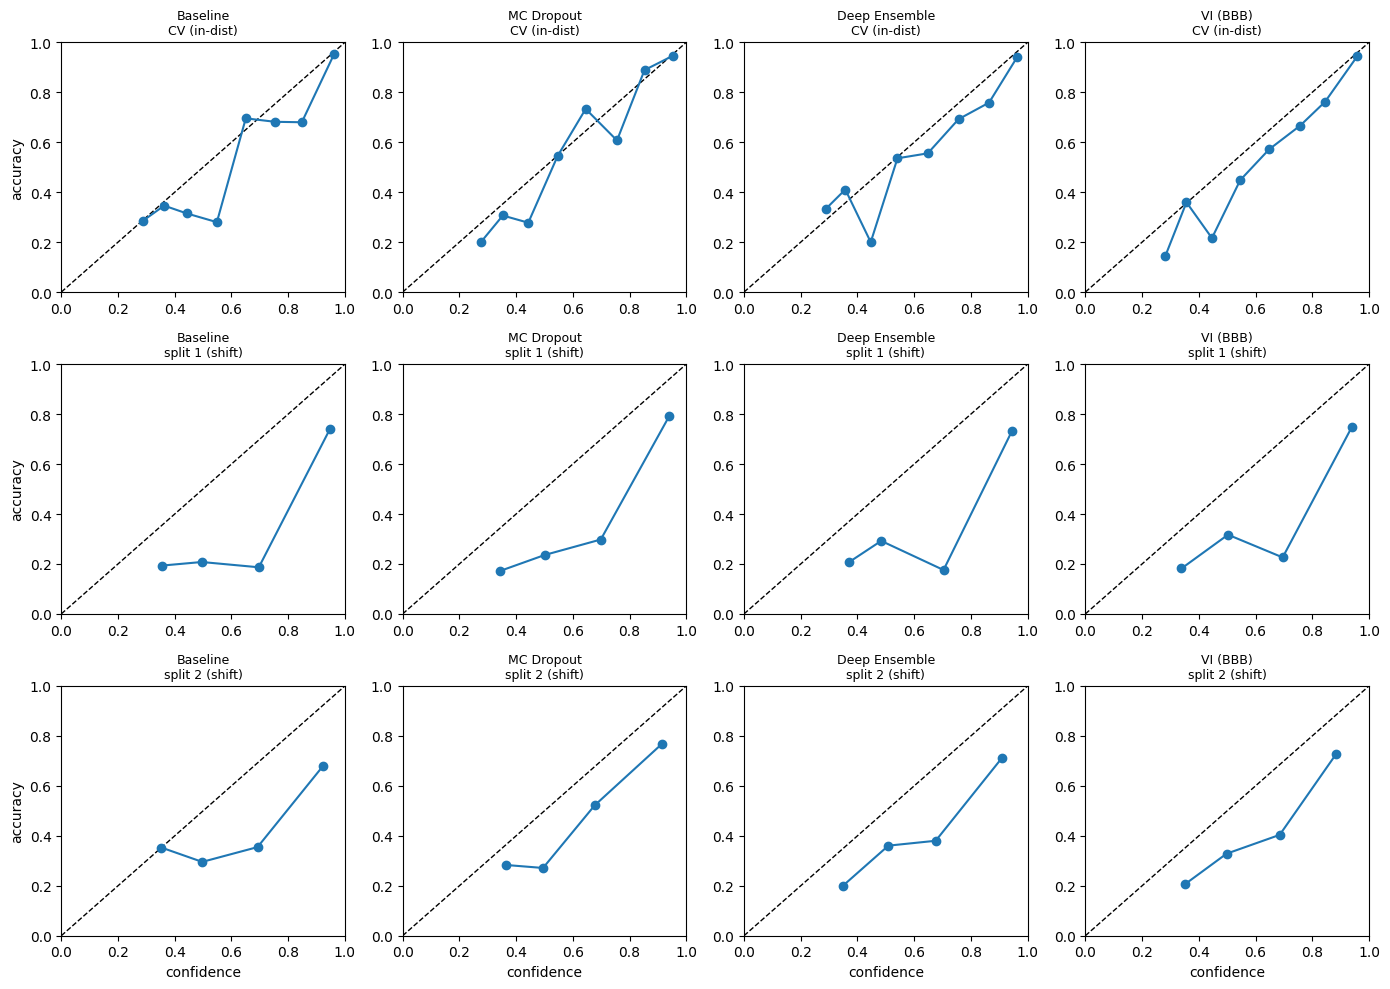

In [42]:
def rel_panel(ax, p, yy, title, n_bins=5, min_n=8):
    conf, correct = p.max(1), (p.argmax(1) == yy).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= min_n:
            xs.append(conf[m].mean()); ys.append(correct[m].mean()); ns.append(m.sum())
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(xs, ys, "o-")
    ax.set_title(title, fontsize=9); ax.set_xlim(0, 1); ax.set_ylim(0, 1)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for j, n in enumerate(names):
    rel_panel(axes[0, j], methods[n], y, f"{n}\nCV (in-dist)", n_bins=10, min_n=5)
    rel_panel(axes[1, j], np.concatenate([shift[s][n] for s in seeds]),  np.tile(yt,  len(seeds)), f"{n}\nsplit 1 (shift)")
    rel_panel(axes[2, j], np.concatenate([shift2[s][n] for s in seeds]), np.tile(yt2, len(seeds)), f"{n}\nsplit 2 (shift)")
for ax in axes[-1]: ax.set_xlabel("confidence")
for ax in axes[:, 0]: ax.set_ylabel("accuracy")
plt.tight_layout()
plt.savefig("../results/figures/reliability_indist_vs_shift.png", dpi=150)
plt.show()